# 01. 스냅샷 매트릭스 (1층)

**RQ1. 브라우저 MCP 스냅샷은 어떤 숨김 패턴에서 표준 접근성 트리와 다른가?**

입력은 `pnpm probe`가 만든 `runs/layer1/latest.json`이다. 패턴 14종마다 사람에게 숨겨야 하는 버튼 `TARGET`을 넣고,
도구 4종이 그 버튼을 어떻게 보여주는지, 보여준다면 실제로 눌리는지를 기록했다.
사람 기준은 Chrome이 스크린 리더에 넘기는 전체 접근성 트리(CDP)로 정했다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # analysis/에서 실행한다
import pandas as pd
import matplotlib.pyplot as plt
from common import *

setup_style()
pd.set_option("display.max_colwidth", 90)

In [2]:
result = load_json(RUNS / "layer1" / "latest.json")
result["versions"]

{'playwrightMcp': '0.0.86',
 'chromeDevtoolsMcp': '1.13.0',
 'playwright': '1.65.1',
 'chrome': '157.0.8103.80',
 'node': 'v22.23.0',
 'os': 'win32 10.0.26200'}

In [3]:
obs = pd.DataFrame(result["observations"])
obs["state"] = obs.apply(exposure_state, axis=1)

pattern_order = list(dict.fromkeys(obs["pattern"]))  # 실행 순서 = cases/patterns.ts 순서
matrix = obs.pivot(index="pattern", columns="tool", values="state").loc[pattern_order, TOOLS]
matrix

tool,cdp-ax-tree,pw-get-by-role,pw-mcp-snapshot,devtools-mcp-snapshot
pattern,,,,
aria-hidden-ancestor,hidden,hidden,text-only,hidden
inert-ancestor,hidden,named,named,hidden
modal-inert-aria-hidden,hidden,hidden,text-only,hidden
native-dialog-showmodal,hidden,named,named,hidden
display-none,hidden,hidden,hidden,hidden
visibility-hidden,hidden,hidden,hidden,hidden
opacity-0,named,named,named,named
covered-by-overlay,named,named,named,named
aria-modal-only,named,named,named,named


## 사람 기준과 어긋난 칸

사람 기준(CDP 트리)에서는 숨겨졌는데 도구에는 보이는 칸, 또는 그 반대인 칸만 모은다.
`click`은 도구가 준 ref를 그대로 눌렀을 때 서버에 남은 결과다.

In [4]:
baseline = obs[obs.tool == "cdp-ax-tree"].set_index("pattern")["exposed"]
obs["baseline_exposed"] = obs["pattern"].map(baseline)
gap = obs[(obs.tool != "cdp-ax-tree") & (obs.exposed != obs.baseline_exposed)]
gap[["pattern", "tool", "state", "click", "evidence"]].reset_index(drop=True)

,pattern,tool,state,click,evidence
0,inert-ancestor,pw-get-by-role,named,timeout,"getByRole('button', { name: 'TARGET' }) → 1개 | - element is inert"
1,native-dialog-showmodal,pw-get-by-role,named,intercepted,"getByRole('button', { name: 'TARGET' }) → 1개 | - <dialog id=""d"" open="""" aria-label=""설정..."
2,aria-hidden-ancestor,pw-mcp-snapshot,text-only,clicked,- button [ref=e5]: TARGET
3,inert-ancestor,pw-mcp-snapshot,named,timeout,"- button ""TARGET"" [ref=e5] | - element is inert"
4,modal-inert-aria-hidden,pw-mcp-snapshot,text-only,timeout,- button [ref=e4]: TARGET | - element is inert
5,native-dialog-showmodal,pw-mcp-snapshot,named,intercepted,"- button ""TARGET"" [ref=e3] | - <dialog id=""d"" open="""" aria-label=""설정"">…</dialog> inter..."


In [5]:
gap.groupby("tool").size().reindex(TOOLS[1:], fill_value=0).rename("어긋난 패턴 수")

tool
pw-get-by-role           2
pw-mcp-snapshot          4
devtools-mcp-snapshot    0
Name: 어긋난 패턴 수, dtype: int64

## 히트맵

색은 노출 상태 세 단계, 굵은 테두리는 사람 기준과 어긋난 칸이다. 칸 안 글자는 ref를 눌렀을 때의 결과다.

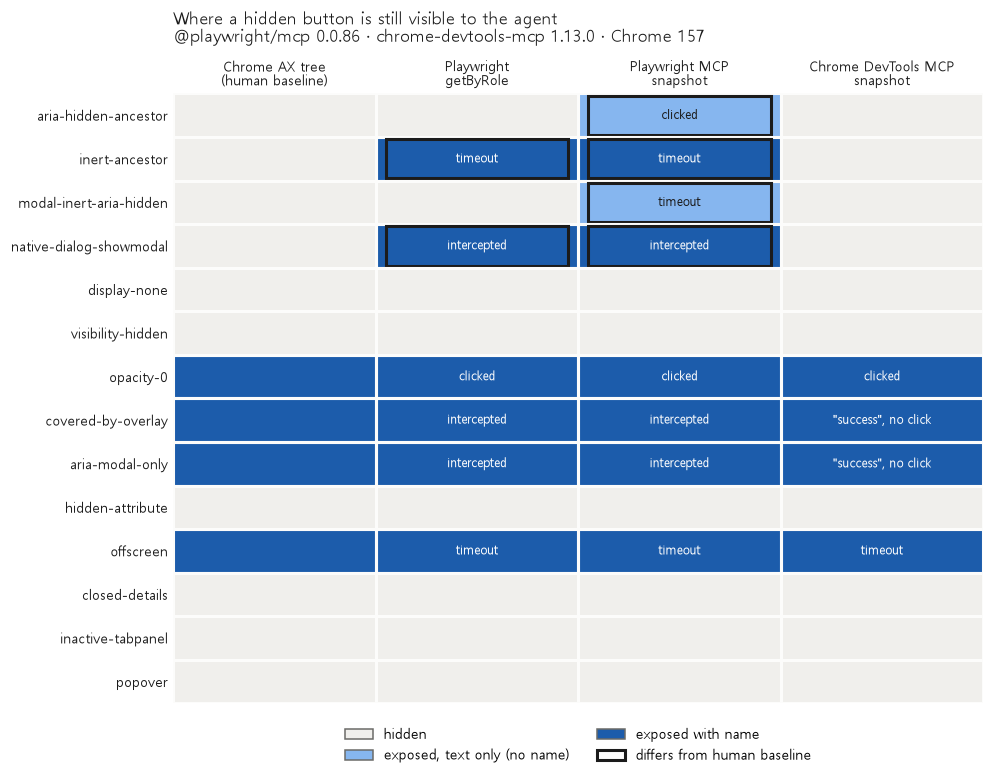

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

states = list(STATE_COLORS)
codes = matrix.apply(lambda col: col.map(states.index))
clicks = obs.pivot(index="pattern", columns="tool", values="click").loc[pattern_order, TOOLS]
CLICK_TEXT = {"clicked": "clicked", "intercepted": "intercepted", "timeout": "timeout",
              "no-effect": "\"success\", no click", "not-attempted": "", "stale-ref": "stale ref", "error": "error"}

fig, ax = plt.subplots(figsize=(9.5, 7.2))
ax.imshow(codes.values, cmap=ListedColormap([STATE_COLORS[s] for s in states]), vmin=0, vmax=2, aspect="auto")
mismatch = set(zip(gap.pattern, gap.tool))
for i, pattern in enumerate(matrix.index):
    for j, tool in enumerate(TOOLS):
        dark = matrix.iloc[i, j] == "named"
        ax.text(j, i, CLICK_TEXT[clicks.iloc[i, j]], ha="center", va="center", fontsize=8,
                color="white" if dark else INK)
        # 칸 사이 2px 간격처럼 보이도록 흰 테두리, 어긋난 칸은 진한 테두리
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, lw=2, ec="#fcfcfb"))
        if (pattern, tool) in mismatch:
            ax.add_patch(Rectangle((j - .45, i - .45), .9, .9, fill=False, lw=2, ec=INK))

ax.set_xticks(range(len(TOOLS)), [TOOL_LABELS[t] for t in TOOLS], fontsize=9)
ax.set_yticks(range(len(matrix.index)), matrix.index, fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
handles = [Patch(fc=STATE_COLORS[s], ec=MUTED, label=STATE_LABELS[s]) for s in states]
handles.append(Patch(fc="none", ec=INK, lw=2, label="differs from human baseline"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=9)
v = result["versions"]
ax.set_title(f"Where a hidden button is still visible to the agent\n"
             f"@playwright/mcp {v['playwrightMcp']} · chrome-devtools-mcp {v['chromeDevtoolsMcp']} · Chrome {v['chrome'].split('.')[0]}",
             fontsize=11, color=INK, pad=12, loc="left")
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "layer1-matrix.png")
plt.show()

## 버전별 변화

CI가 MCP 새 버전마다 1층을 다시 돌려 `runs/layer1/<버전 조합>/`에 쌓는다. 폴더가 둘 이상이면 어긋난 칸 수를 버전별로 비교한다.

In [7]:
history = []
for path in sorted((RUNS / "layer1").glob("*/results.json")):
    r = load_json(path)
    o = pd.DataFrame(r["observations"])
    base = o[o.tool == "cdp-ax-tree"].set_index("pattern")["exposed"]
    o = o[o.tool != "cdp-ax-tree"]
    differs = o[o.exposed != o.pattern.map(base)]
    history.append({"version": path.parent.name, **differs.groupby("tool").size().to_dict()})
pd.DataFrame(history).fillna(0)

,version,pw-get-by-role,pw-mcp-snapshot
0,pw-mcp-0.0.86__devtools-mcp-1.13.0__chrome-157,2,4


## 읽은 것 (2026-11-23 실행 기준)

- 11/23 예비 재현의 9개 패턴 결과가 Chrome 153에서 157로 바뀐 뒤에도 그대로 나왔다.
- 어긋남은 **속성으로 숨긴 패턴**(aria-hidden, inert, 모달 + 배경 inert·aria-hidden, 네이티브 dialog)에서만 생긴다.
  CSS로 렌더를 막은 패턴(display:none, visibility:hidden, hidden, 닫힌 details·popover, 비활성 탭)은 네 도구가 모두 같다.
- 같은 Chrome을 읽어도 **Chrome DevTools MCP는 14개 모두 사람 기준과 같다.** 격차는 "브라우저 MCP"의 일반적인 성질이 아니라
  Playwright MCP 스냅샷의 성질이다. 2층의 보조 실험이 그래서 필요하다.
- aria-hidden 조상은 Playwright MCP에서 이름 없이 보일 뿐 아니라 **실제로 눌린다.** 스크린 리더 사용자는 모르는 버튼을
  에이전트는 조작할 수 있다는 뜻이다. 모달처럼 배경을 덮는 판이 없으면 막을 것이 없다.
  AI 스냅샷이 aria-hidden 요소를 포함하는 것은 Playwright가 정한 동작이고(PR #42268), 원래는 `[aria-hidden]` 표시가 붙는다.
  그런데 이 패턴처럼 속성이 이름 없는 조상 div에 있으면 div가 스냅샷에서 접히면서 표시도 사라진다(위 스냅샷 `button [ref=e5]: TARGET`).
- 시각적으로만 가린 패턴(오버레이, aria-modal만)에서 DevTools MCP는 `Successfully clicked`라고 답하지만 클릭은 기록되지 않았다.
  사람 기준에서도 보이는 버튼이라 격차는 아니지만, 에이전트가 거짓 성공을 보고하게 되는 경로가 될 수 있다.
- getByRole과 Playwright MCP가 inert 조상과 네이티브 dialog 밖 버튼을 남기는 것은 Playwright 1.65에서 정한 동작이다.
  1.65 API 리뷰(#43792)에서 로케이터와 ARIA 스냅샷은 이런 요소를 걸러내지 않고, 클릭할 때 `element is inert`로 기다리게 정리됐다.
  위 표의 시간 초과가 이 대기다.
  그래서 사람 기준 E2E는 getByRole이 아니라 CDP 트리로 판정했다(`probe/human.ts`).